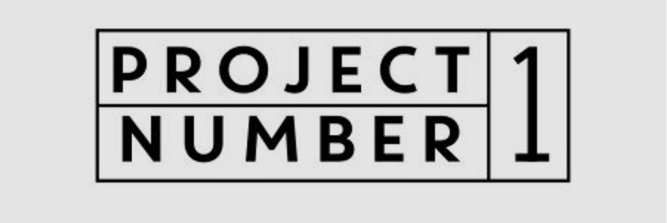

In [1]:
import kagglehub
import pandas as pd
import os

# Download latest version
path = kagglehub.dataset_download("blastchar/telco-customer-churn")
print("Path to dataset files:", path)

# List what's actually in the folder (usually one CSV)
print(os.listdir(path))

# Load it — the file is typically named:
# WA_Fn-UseC_-Telco-Customer-Churn.csv
csv_file = [f for f in os.listdir(path) if f.endswith(".csv")][0]
df = pd.read_csv(os.path.join(path, csv_file))

print(df.shape)
print(df.columns.tolist())
df.head()

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Path to dataset files: /kaggle/input/telco-customer-churn
['WA_Fn-UseC_-Telco-Customer-Churn.csv']
(7043, 21)
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [4]:
df['customerID'].count()

np.int64(7043)

In [5]:
##cleaning step-1
df_filled = df.fillna(0)
df_filled['tenure'].count()
df_filled[
    df_filled['tenure']== 1
]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
20,8779-QRDMV,Male,1,No,No,1,No,No phone service,DSL,No,...,Yes,No,No,Yes,Month-to-month,Yes,Electronic check,39.65,39.65,Yes
22,1066-JKSGK,Male,0,No,No,1,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.15,20.15,Yes
27,8665-UTDHZ,Male,0,Yes,Yes,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,No,Electronic check,30.20,30.2,Yes
33,7310-EGVHZ,Male,0,No,No,1,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Bank transfer (automatic),20.20,20.2,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6979,5351-QESIO,Male,0,No,Yes,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,No,Mailed check,24.20,24.2,No
7010,0723-DRCLG,Female,1,Yes,No,1,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,74.45,74.45,Yes
7016,1471-GIQKQ,Female,0,No,No,1,Yes,No,DSL,No,...,No,No,No,No,Month-to-month,No,Electronic check,49.95,49.95,No
7018,1122-JWTJW,Male,0,Yes,Yes,1,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,70.65,70.65,Yes


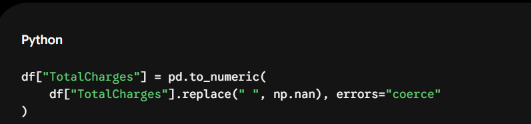

In [6]:
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'].replace('',np.nan), errors='coerce'
)
df= df.fillna(0)
df['TotalCharges']
df


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes


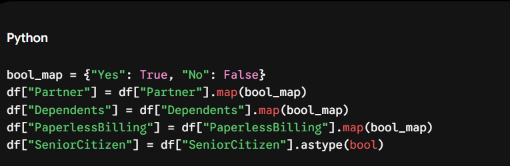

In [7]:
bool_map = { "yes": True, "no": False}
df['Partner'] = df["Partner"].map(bool_map)
df['Dependents'] = df["Dependents"].map(bool_map)
df['PaperlessBilling'] = df['PaperlessBilling'].map(bool_map)
df['SeniorCitizen'] = df['SeniorCitizen'].map(bool_map)

df=df.fillna(0)
df

/tmp/ipykernel_2803/1375817093.py:7: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df=df.fillna(0)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,0,0,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,0,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,0,0,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,0,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,0,0,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,0,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,0,0,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,0,0,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,0,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,0,0,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,0,Mailed check,84.80,1990.50,No
7039,2234-XADUH,Female,0,0,0,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,0,Credit card (automatic),103.20,7362.90,No
7040,4801-JZAZL,Female,0,0,0,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,0,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,0,0,0,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,0,Mailed check,74.40,306.60,Yes


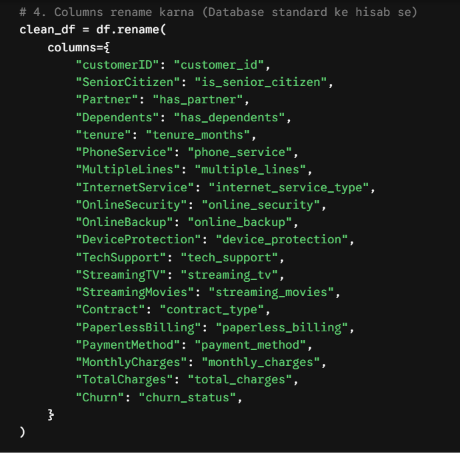

In [8]:
clean_df = df.rename(
    columns={
        "customerID": "customer_id",
        "SeniorCitizen": "is_senior_citizen",
        "Partner": "has_partner",
        "Dependents": "has_dependents",
        "tenure": "tenure_months",
        "PhoneService": "phone_service",
        "MultipleLines": "multiple_lines",
        "InternetService": "internet_service_type",
        "OnlineSecurity": "online_security",
        "OnlineBackup": "online_backup",
        "DeviceProtection": "device_protection",
        "TechSupport": "tech_support",
        "StreamingTV": "streaming_tv",
        "StreamingMovies": "streaming_movies",
        "Contract": "contract_type",
        "PaperlessBilling": "paperless_billing",
        "PaymentMethod": "payment_method",
        "MonthlyCharges": "monthly_charges",
        "TotalCharges": "total_charges",
        "Churn": "churn_status",
    }
)
df = clean_df
df

,customer_id,gender,is_senior_citizen,has_partner,has_dependents,tenure_months,phone_service,multiple_lines,internet_service_type,online_security,...,device_protection,tech_support,streaming_tv,streaming_movies,contract_type,paperless_billing,payment_method,monthly_charges,total_charges,churn_status
0,7590-VHVEG,Female,0,0,0,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,0,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,0,0,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,0,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,0,0,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,0,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,0,0,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,0,0,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,0,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,0,0,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,0,Mailed check,84.80,1990.50,No
7039,2234-XADUH,Female,0,0,0,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,0,Credit card (automatic),103.20,7362.90,No
7040,4801-JZAZL,Female,0,0,0,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,0,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,0,0,0,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,0,Mailed check,74.40,306.60,Yes


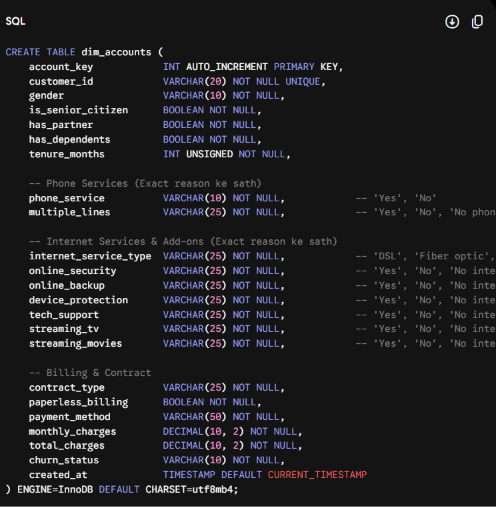

In [9]:
df

,customer_id,gender,is_senior_citizen,has_partner,has_dependents,tenure_months,phone_service,multiple_lines,internet_service_type,online_security,...,device_protection,tech_support,streaming_tv,streaming_movies,contract_type,paperless_billing,payment_method,monthly_charges,total_charges,churn_status
0,7590-VHVEG,Female,0,0,0,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,0,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,0,0,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,0,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,0,0,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,0,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,0,0,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,0,0,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,0,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,0,0,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,0,Mailed check,84.80,1990.50,No
7039,2234-XADUH,Female,0,0,0,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,0,Credit card (automatic),103.20,7362.90,No
7040,4801-JZAZL,Female,0,0,0,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,0,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,0,0,0,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,0,Mailed check,74.40,306.60,Yes


In [10]:
dim_accounts = df[['customer_id','tenure_months','contract_type','paperless_billing','payment_method','monthly_charges','total_charges']]


In [11]:
fact_subscription = df[[ 'customer_id', 'tenure_months', 'monthly_charges', 'total_charges']]
fact_subscription

,customer_id,tenure_months,monthly_charges,total_charges
0,7590-VHVEG,1,29.85,29.85
1,5575-GNVDE,34,56.95,1889.50
2,3668-QPYBK,2,53.85,108.15
3,7795-CFOCW,45,42.30,1840.75
4,9237-HQITU,2,70.70,151.65
...,...,...,...,...
7038,6840-RESVB,24,84.80,1990.50
7039,2234-XADUH,72,103.20,7362.90
7040,4801-JZAZL,11,29.60,346.45
7041,8361-LTMKD,4,74.40,306.60


In [12]:
print(dim_accounts.info())
print(fact_subscription.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        7043 non-null   object 
 1   tenure_months      7043 non-null   int64  
 2   contract_type      7043 non-null   object 
 3   paperless_billing  7043 non-null   int64  
 4   payment_method     7043 non-null   object 
 5   monthly_charges    7043 non-null   float64
 6   total_charges      7043 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 385.3+ KB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   customer_id      7043 non-null   object 
 1   tenure_months    7043 non-null   int64  
 2   monthly_charges  7043 non-null   float64
 3   total_charges    7043 non-null   float64
dtypes: flo

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   customer_id            7043 non-null   object 
 1   gender                 7043 non-null   object 
 2   is_senior_citizen      7043 non-null   int64  
 3   has_partner            7043 non-null   int64  
 4   has_dependents         7043 non-null   int64  
 5   tenure_months          7043 non-null   int64  
 6   phone_service          7043 non-null   object 
 7   multiple_lines         7043 non-null   object 
 8   internet_service_type  7043 non-null   object 
 9   online_security        7043 non-null   object 
 10  online_backup          7043 non-null   object 
 11  device_protection      7043 non-null   object 
 12  tech_support           7043 non-null   object 
 13  streaming_tv           7043 non-null   object 
 14  streaming_movies       7043 non-null   object 
 15  cont

In [14]:
import pandas as pd
import numpy as np
import random
import uuid
from datetime import datetime, timedelta

In [15]:
df['contract_type']

,contract_type
0,Month-to-month
1,One year
2,Month-to-month
3,One year
4,Month-to-month
...,...
7038,One year
7039,One year
7040,Month-to-month
7041,Month-to-month


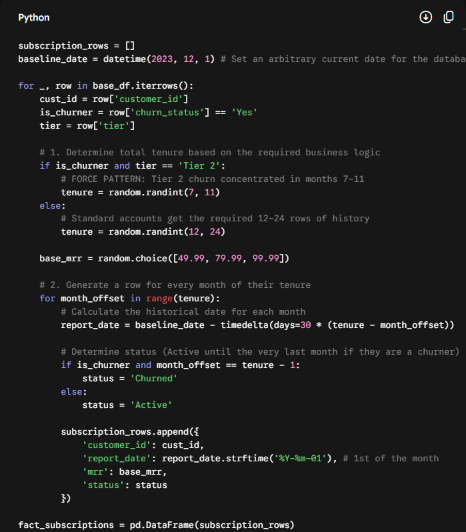

In [16]:
subscription_rows = []
baseline_date = datetime(2023, 12, 1)

for _, row in df.iterrows():
    cust_id = row['customer_id']
    is_churner = row['churn_status'] == 'Yes'


    if is_churner:
        tenure = random.randint(7, 11)
    else:
        tenure = random.randint(12, 24)

    base_mrr = random.choice([49.99, 79.99, 99.99])

    for month_offset in range(tenure):

        report_date = baseline_date - timedelta(days=30 * (tenure - month_offset))


        if is_churner and month_offset == tenure - 1:
            status = 'Churned'
        else:
            status = 'Active'

        subscription_rows.append({
            'customer_id': cust_id,
            'report_date': report_date.strftime('%Y-%m-01'),
            'mrr': base_mrr,
            'status': status
        })

fact_subscriptions = pd.DataFrame(subscription_rows)

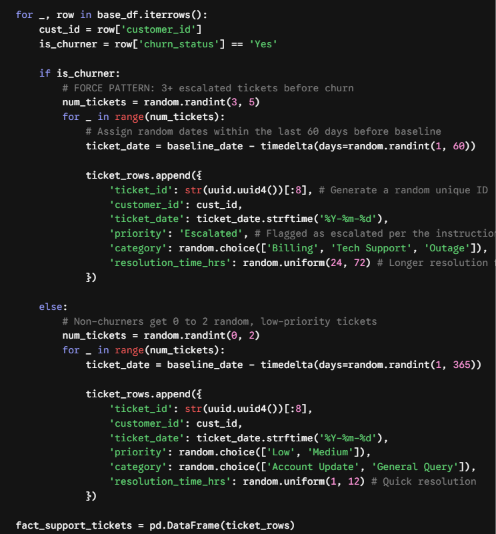

In [17]:
ticket_rows = []

for _, row in df.iterrows():
    cust_id = row['customer_id']
    is_churner = row['churn_status'] == 'Yes'

    if is_churner:

        num_tickets = random.randint(3, 5)
        for _ in range(num_tickets):

            ticket_date = baseline_date - timedelta(days=random.randint(1, 60))

            ticket_rows.append({
                'ticket_id': str(uuid.uuid4())[:8],
                'customer_id': cust_id,
                'ticket_date': ticket_date.strftime('%Y-%m-%d'),
                'priority': 'Escalated',
                'category': random.choice(['Billing', 'Tech Support', 'Outage']),
                'resolution_time_hrs': random.uniform(24, 72)
            })

    else:

        num_tickets = random.randint(0, 2)
        for _ in range(num_tickets):
            ticket_date = baseline_date - timedelta(days=random.randint(1, 365))

            ticket_rows.append({
                'ticket_id': str(uuid.uuid4())[:8],
                'customer_id': cust_id,
                'ticket_date': ticket_date.strftime('%Y-%m-%d'),
                'priority': random.choice(['Low', 'Medium']),
                'category': random.choice(['Account Update', 'General Query']),
                'resolution_time_hrs': random.uniform(1, 12)
            })

fact_support_tickets = pd.DataFrame(ticket_rows)

In [18]:
fact_subscription

,customer_id,tenure_months,monthly_charges,total_charges
0,7590-VHVEG,1,29.85,29.85
1,5575-GNVDE,34,56.95,1889.50
2,3668-QPYBK,2,53.85,108.15
3,7795-CFOCW,45,42.30,1840.75
4,9237-HQITU,2,70.70,151.65
...,...,...,...,...
7038,6840-RESVB,24,84.80,1990.50
7039,2234-XADUH,72,103.20,7362.90
7040,4801-JZAZL,11,29.60,346.45
7041,8361-LTMKD,4,74.40,306.60


In [19]:
dim_accounts.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        7043 non-null   object 
 1   tenure_months      7043 non-null   int64  
 2   contract_type      7043 non-null   object 
 3   paperless_billing  7043 non-null   int64  
 4   payment_method     7043 non-null   object 
 5   monthly_charges    7043 non-null   float64
 6   total_charges      7043 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 385.3+ KB


In [20]:
fact_support_tickets.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12686 entries, 0 to 12685
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ticket_id            12686 non-null  object 
 1   customer_id          12686 non-null  object 
 2   ticket_date          12686 non-null  object 
 3   priority             12686 non-null  object 
 4   category             12686 non-null  object 
 5   resolution_time_hrs  12686 non-null  float64
dtypes: float64(1), object(5)
memory usage: 594.8+ KB


In [21]:
df1= fact_support_tickets
df1[
    df1['customer_id'] == '2232-DMLXU'
]

,ticket_id,customer_id,ticket_date,priority,category,resolution_time_hrs
386,1eb01e64,2232-DMLXU,2023-11-15,Escalated,Billing,47.226722
387,dbece908,2232-DMLXU,2023-11-19,Escalated,Outage,28.758922
388,843c7889,2232-DMLXU,2023-10-16,Escalated,Outage,35.456588
389,fd1f0f2b,2232-DMLXU,2023-11-20,Escalated,Outage,28.818641
